# Matrix Factorization dengan Stochastic Gradient Descent (SGD-MF)
Tugas Kelompok Sistem Rekomendasi, bagian Matrix Factorization

Pada notebook ini kami membuat model Matrix Factorization yang dilatih dengan Stochastic Gradient Descent (SGD), lalu memakainya untuk memprediksi rating dan membuat rekomendasi film pada dataset MovieLens ml-latest-small.

Ada dua varian yang kami coba:
1. SGD-MF tanpa bias: rating diprediksi langsung dari $\hat{R} \approx PQ^T$.
2. SGD-MF dengan bias: prediksi ditambah rata-rata global $\mu$, bias user $b_u$, dan bias item $b_i$ (Koren dkk., 2009).

Evaluasi memakai MAE, MSE, RMSE, NMSE, dan NDCG. Untuk rekomendasi top-10 kami juga menghitung Precision, Recall, dan F1.

## 1. Setup dan Data
Library yang dipakai hanya `numpy`, `pandas`, dan `matplotlib`. Seed diset 42 supaya hasilnya bisa diulang. Dataset ml-latest-small akan diunduh otomatis kalau belum ada. Kalau unduhan gagal, file `ml-latest-small.zip` bisa diletakkan manual di folder `data/`. Folder data dicari di `../data`, atau di `data` kalau notebook dijalankan di Google Colab.

In [1]:
import os
# batasi BLAS ke 1 thread (untuk matriks kecil, multi-thread malah lebih lambat). harus sebelum import numpy
for var in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ[var] = "1"

import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

DATA_DIR = "../data" if os.path.isdir("../data") else "data"
ML_DIR = os.path.join(DATA_DIR, "ml-latest-small")
SPLIT_DIR = os.path.join(DATA_DIR, "split")
RESULTS_DIR = "results"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

if not os.path.exists(os.path.join(ML_DIR, "ratings.csv")):
    zip_path = os.path.join(DATA_DIR, "ml-latest-small.zip")
    if not os.path.exists(zip_path):
        print("Mengunduh ml-latest-small ...")
        urllib.request.urlretrieve("https://files.grouplens.org/datasets/movielens/ml-latest-small.zip", zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(DATA_DIR)

R_MIN, R_MAX = 0.5, 5.0   # skala rating ml-latest-small

BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
INK, MUTED = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.axisbelow": True,
})

ratings = pd.read_csv(os.path.join(ML_DIR, "ratings.csv"))
movies = pd.read_csv(os.path.join(ML_DIR, "movies.csv"))
title_of = dict(zip(movies.movieId, movies.title))
print(f"{ratings.userId.nunique()} user, {ratings.movieId.nunique()} film, {len(ratings)} rating "
      f"(sparsity {1 - len(ratings) / (ratings.userId.nunique() * ratings.movieId.nunique()):.2%})")

610 user, 9724 film, 100836 rating (sparsity 98.30%)


## 2. Pembagian Data Train, Validasi, dan Test
Semua anggota kelompok memakai pembagian data yang sama (`data/split/train.csv` dan `test.csv`). Untuk setiap user, 20% ratingnya diambil acak sebagai data test (seed 42). Kalau file tersebut belum ada, sel ini akan membuatnya dengan fungsi yang sama seperti `bersama/buat_split.py`.

Untuk tuning hyperparameter, 10% dari data train disisihkan sebagai data validasi, sehingga data test tidak ikut dipakai saat memilih parameter. `userId` dan `movieId` dipetakan ke indeks 0 sampai n-1.

In [2]:
def split_per_user(ratings, test_frac=0.2, seed=42):
    rng = np.random.default_rng(seed)
    test_idx = []
    for _, idx in sorted(ratings.groupby("userId").indices.items()):
        test_idx.extend(rng.choice(idx, size=int(round(len(idx) * test_frac)), replace=False))
    is_test = np.zeros(len(ratings), dtype=bool)
    is_test[test_idx] = True
    return ratings[~is_test].reset_index(drop=True), ratings[is_test].reset_index(drop=True)

if not os.path.exists(os.path.join(SPLIT_DIR, "train.csv")):
    os.makedirs(SPLIT_DIR, exist_ok=True)
    _tr, _te = split_per_user(ratings)
    _tr.to_csv(os.path.join(SPLIT_DIR, "train.csv"), index=False)
    _te.to_csv(os.path.join(SPLIT_DIR, "test.csv"), index=False)

train_full = pd.read_csv(os.path.join(SPLIT_DIR, "train.csv"))
test = pd.read_csv(os.path.join(SPLIT_DIR, "test.csv"))

user_ids = np.sort(ratings.userId.unique())
item_ids = np.sort(ratings.movieId.unique())
u_index = {x: n for n, x in enumerate(user_ids)}
i_index = {x: n for n, x in enumerate(item_ids)}
for df in (train_full, test):
    df["u"] = df.userId.map(u_index)
    df["i"] = df.movieId.map(i_index)
N_USERS, N_ITEMS = len(user_ids), len(item_ids)

rng = np.random.default_rng(SEED)
perm = rng.permutation(len(train_full))
n_val = int(0.1 * len(train_full))
val = train_full.iloc[perm[:n_val]].reset_index(drop=True)
train = train_full.iloc[perm[n_val:]].reset_index(drop=True)
n_rating_item = np.bincount(train_full.i, minlength=N_ITEMS)

print(f"train_full: {len(train_full)} | train: {len(train)} | val: {len(val)} | test: {len(test)} rating")

train_full: 80672 | train: 72605 | val: 8067 | test: 20164 rating


## 3. Metrik Evaluasi
Metrik yang dipakai:

| Metrik | Rumus |
|---|---|
| MAE | $\frac{1}{N}\sum \lvert r_{ui}-\hat{r}_{ui}\rvert$ |
| MSE | $\frac{1}{N}\sum (r_{ui}-\hat{r}_{ui})^2$ |
| RMSE | $\sqrt{\text{MSE}}$ |
| NMSE | $\text{MSE} / (r_{max}-r_{min})^2 = \text{MSE}/4.5^2$ |
| NDCG@k | untuk tiap user, film di data test diurutkan menurut skor model, relevansinya adalah rating asli. $DCG=\sum rel_j/\log_2(j+1)$, lalu dibagi IDCG |
| Precision/Recall/F1@k | k film teratas dari semua film yang belum dirating user. Film dianggap relevan kalau ada di data test dengan rating ≥ 4 |

In [3]:
def mae(y, y_hat):  return np.mean(np.abs(y - y_hat))
def mse(y, y_hat):  return np.mean((y - y_hat) ** 2)
def rmse(y, y_hat): return np.sqrt(mse(y, y_hat))
def nmse(y, y_hat): return mse(y, y_hat) / (R_MAX - R_MIN) ** 2

def ndcg_at_k(df, pred_col, k=10):
    discounts = 1 / np.log2(np.arange(2, k + 2))
    scores = []
    for _, g in df.groupby("userId"):
        rel_pred = g.sort_values(pred_col, ascending=False, kind="stable").rating.values[:k]
        rel_ideal = np.sort(g.rating.values)[::-1][:k]
        scores.append(np.sum(rel_pred * discounts[:len(rel_pred)]) / np.sum(rel_ideal * discounts[:len(rel_ideal)]))
    return np.mean(scores)

def precision_recall_f1_at_k(recs, test_df, k=10, threshold=4.0):
    relevant = test_df[test_df.rating >= threshold].groupby("userId").movieId.apply(set).to_dict()
    P, Rc = [], []
    for user, rel in relevant.items():
        hit = len(set(recs.get(user, [])[:k]) & rel)
        P.append(hit / k); Rc.append(hit / len(rel))
    p, r = np.mean(P), np.mean(Rc)
    return p, r, (2 * p * r / (p + r) if p + r > 0 else 0.0)

def rating_metrics(df, pred_col):
    y, y_hat = df.rating.values.astype(float), df[pred_col].values
    return {"MAE": mae(y, y_hat), "MSE": mse(y, y_hat), "RMSE": rmse(y, y_hat), "NMSE": nmse(y, y_hat)}

def top_n_from_scores(S, train_df, n=10):
    # ambil n film dengan skor tertinggi yang belum dirating user. kalau skor sama, movieId kecil duluan
    S = S.astype(float).copy()
    in_train = np.zeros(N_ITEMS, dtype=bool)
    in_train[train_df.i.unique()] = True
    S[:, ~in_train] = -np.inf
    S[train_df.u.values, train_df.i.values] = -np.inf
    top = np.argsort(-S, axis=1, kind="stable")[:, :n]
    return {user_ids[u]: list(item_ids[top[u]]) for u in range(N_USERS)}

def topn_metrics(S, train_df, test_df, ns=(5, 10, 20)):
    out = {}
    for n in ns:
        p, r, f = precision_recall_f1_at_k(top_n_from_scores(S, train_df, n), test_df, k=n)
        out.update({f"Precision@{n}": p, f"Recall@{n}": r, f"F1@{n}": f})
    return out

# simpan hasil dengan format yang disepakati kelompok
def save_predictions(df, pred_col, name):        # userId, movieId, rating, pred
    df[["userId", "movieId", "rating", pred_col]].rename(columns={pred_col: "pred"}).to_csv(
        os.path.join(RESULTS_DIR, f"prediksi_test_{name}.csv"), index=False)

def save_scores(S, name):                        # userId, movieId, rating, score (untuk NDCG model top-N)
    test[["userId", "movieId", "rating"]].assign(score=S[test.u.values, test.i.values]).to_csv(
        os.path.join(RESULTS_DIR, f"skor_test_{name}.csv"), index=False)

def save_top10(S, name):                         # userId, rank, movieId
    rc = top_n_from_scores(S, train_full, 10)
    pd.DataFrame([(uid, rank + 1, mid) for uid, lst in rc.items() for rank, mid in enumerate(lst)],
                 columns=["userId", "rank", "movieId"]).to_csv(
        os.path.join(RESULTS_DIR, f"rekomendasi_top10_{name}.csv"), index=False)

S_POP = np.tile(n_rating_item.astype(float), (N_USERS, 1))   # baseline populer: skor = jumlah rating film di train

## 4. Uji Coba pada Matriks Kecil
Sebelum dipakai ke dataset asli, algoritmanya kami coba dulu pada matriks rating 5×4 (5 user, 4 film, angka 0 berarti belum dirating) dengan $k = 2$ faktor laten, `steps=5000`, `alpha=0.0002`, dan `beta=0.02`.

Untuk setiap rating yang ada, error dihitung sebagai $e_{ij} = r_{ij} - p_i^T q_j$, kemudian $P$ dan $Q$ diperbarui dengan aturan:
$$p_{ik} \leftarrow p_{ik} + \alpha\,(2\,e_{ij}\,q_{kj} - \beta\,p_{ik}), \qquad q_{kj} \leftarrow q_{kj} + \alpha\,(2\,e_{ij}\,p_{ik} - \beta\,q_{kj})$$
dengan $\alpha$ sebagai learning rate dan $\beta$ sebagai parameter regularisasi.

In [4]:
def matrix_factorization(R, P, Q, K, steps=5000, alpha=0.0002, beta=0.02):
    Q = Q.T
    for step in range(steps):
        for i in range(len(R)):
            for j in range(len(R[i])):
                if R[i][j] > 0:
                    eij = R[i][j] - np.dot(P[i, :], Q[:, j])
                    for k in range(K):
                        P[i][k] = P[i][k] + alpha * (2 * eij * Q[k][j] - beta * P[i][k])
                        Q[k][j] = Q[k][j] + alpha * (2 * eij * P[i][k] - beta * Q[k][j])
        # hitung total error (dengan regularisasi), berhenti kalau sudah sangat kecil
        e = 0
        for i in range(len(R)):
            for j in range(len(R[i])):
                if R[i][j] > 0:
                    e = e + pow(R[i][j] - np.dot(P[i, :], Q[:, j]), 2)
                    for k in range(K):
                        e = e + (beta / 2) * (pow(P[i][k], 2) + pow(Q[k][j], 2))
        if e < 0.001:
            break
    return P, Q.T

R_toy = np.array([[5, 3, 0, 1], [4, 0, 0, 1], [1, 1, 0, 5], [1, 0, 0, 4], [0, 1, 5, 4]])
N, M, K = len(R_toy), len(R_toy[0]), 2
np.random.seed(SEED)
P0 = np.random.rand(N, K)
Q0 = np.random.rand(M, K)

t0 = time.time()
nP, nQ = matrix_factorization(R_toy, P0, Q0, K)
print(f"Waktu: {time.time() - t0:.1f} detik untuk 5000 step\n")
print("Matriks rating asli:")
print(R_toy)
print("\nMatriks hasil P x Q^T:")
print(np.dot(nP, nQ.T).round(2))

Waktu: 0.6 detik untuk 5000 step

Matriks rating asli:
[[5 3 0 1]
 [4 0 0 1]
 [1 1 0 5]
 [1 0 0 4]
 [0 1 5 4]]

Matriks hasil P x Q^T:
[[5.07 2.75 4.24 1.01]
 [3.92 2.14 3.45 0.99]
 [1.08 0.73 4.69 4.97]
 [0.96 0.63 3.82 3.97]
 [2.47 1.44 4.88 4.02]]


Rating yang sudah ada berhasil didekati dengan cukup baik, misalnya 5 menjadi 5,07 dan 1 menjadi 1,01. Sel yang awalnya 0 sekarang terisi nilai prediksi.

Kode di atas memakai tiga loop bersarang dan memeriksa semua sel matriks, termasuk yang kosong. Untuk 80 ribu rating dan matriks 610 × 9.742 cara ini terlalu lambat, jadi pada implementasi berikutnya kami ubah beberapa hal:
- loop hanya dilakukan pada rating yang ada, bukan semua sel;
- urutan rating diacak ulang di setiap epoch (bagian "stochastic" dari SGD);
- loop per faktor $k$ diganti operasi vektor NumPy;
- di akhir setiap epoch dihitung RMSE pada data train dan validasi.

## 5. Implementasi SGD-MF
Satu epoch berarti satu kali melewati semua rating train dengan urutan acak. Untuk setiap rating $r_{ui}$:

1. Hitung prediksi dan error: $\hat{r}_{ui} = \mu + b_u + b_i + p_u^T q_i$, lalu $e_{ui} = r_{ui} - \hat{r}_{ui}$
2. Perbarui parameter dengan aturan yang sama seperti di bagian 4:
$$b_u \leftarrow b_u + \alpha(2e_{ui} - \beta b_u), \quad b_i \leftarrow b_i + \alpha(2e_{ui} - \beta b_i)$$
$$p_u \leftarrow p_u + \alpha(2e_{ui}\,q_i - \beta p_u), \quad q_i \leftarrow q_i + \alpha(2e_{ui}\,p_u - \beta q_i)$$

Kalau `use_bias=False`, nilai $\mu$, $b_u$, dan $b_i$ tetap 0, dan $P$, $Q$ diinisialisasi dengan `rand` (0 sampai 1) seperti di bagian 4. Kalau `use_bias=True`, $P$ dan $Q$ diinisialisasi dengan bilangan acak normal kecil (simpangan baku 0,1) dan bias dimulai dari 0.

In [5]:
class SGDMF:
    def __init__(self, n_factors=50, alpha=0.005, beta=0.2, n_epochs=30, use_bias=True, seed=42):
        self.k, self.alpha, self.beta, self.n_epochs, self.use_bias, self.seed = n_factors, alpha, beta, n_epochs, use_bias, seed

    def fit(self, train_df, eval_df=None, verbose=False):
        rng = np.random.default_rng(self.seed)
        if self.use_bias:
            self.P = rng.normal(0, 0.1, (N_USERS, self.k))
            self.Q = rng.normal(0, 0.1, (N_ITEMS, self.k))
        else:
            self.P = rng.random((N_USERS, self.k))
            self.Q = rng.random((N_ITEMS, self.k))
        self.bu, self.bi = np.zeros(N_USERS), np.zeros(N_ITEMS)
        u, i = train_df.u.values, train_df.i.values
        r = train_df.rating.values.astype(float)
        self.mu = r.mean() if self.use_bias else 0.0
        self.item_seen = np.bincount(i, minlength=N_ITEMS) > 0
        a, b = self.alpha, self.beta
        P, Q, bu, bi, mu = self.P, self.Q, self.bu, self.bi, self.mu

        self.history = []
        with np.errstate(over="ignore", invalid="ignore"):
            for ep in range(1, self.n_epochs + 1):
                t0 = time.time()
                for idx in rng.permutation(len(r)):              # urutan rating diacak tiap epoch
                    uu, ii = u[idx], i[idx]
                    pu, qi = P[uu].copy(), Q[ii]
                    e = r[idx] - (mu + bu[uu] + bi[ii] + pu @ qi)
                    if self.use_bias:
                        bu[uu] += a * (2 * e - b * bu[uu])
                        bi[ii] += a * (2 * e - b * bi[ii])
                    P[uu] = pu + a * (2 * e * qi - b * pu)
                    Q[ii] = qi + a * (2 * e * pu - b * qi)
                rec = {"epoch": ep, "detik": time.time() - t0, "train_rmse": rmse(r, self.predict(u, i))}
                if eval_df is not None:
                    rec["eval_rmse"] = rmse(eval_df.rating.values, self.predict(eval_df.u.values, eval_df.i.values))
                self.history.append(rec)
                if verbose:
                    print(f"epoch {ep:2d}  train RMSE={rec['train_rmse']:.4f}" +
                          (f"  eval RMSE={rec['eval_rmse']:.4f}" if eval_df is not None else ""))
                if not np.isfinite(rec["train_rmse"]) or rec["train_rmse"] > 10:   # error meledak, berhenti
                    break
        return self

    def score(self, u, i):
        u, i = np.asarray(u), np.asarray(i)
        s = self.mu + self.bu[u] + self.bi[i] + np.sum(self.P[u] * self.Q[i], axis=1)
        if self.use_bias:                       # film yang tidak ada di train cukup pakai mu + b_u
            s = np.where(self.item_seen[i], s, self.mu + self.bu[u])
        return s

    def predict(self, u, i):
        return np.clip(self.score(u, i), R_MIN, R_MAX)

    def score_matrix(self):
        return self.mu + self.bu[:, None] + self.bi[None, :] + self.P @ self.Q.T

## 6. Tuning Hyperparameter
Setiap kombinasi parameter dilatih pada data train, lalu RMSE pada data validasi dicatat di setiap epoch. Kombinasi dan jumlah epoch yang dipilih adalah yang RMSE validasinya paling kecil (early stopping).
- Tanpa bias: $k \in \{10, 50\}$, $\beta \in \{0.1, 0.2\}$, $\alpha = 0.002$, maksimal 30 epoch.
- Dengan bias: $k \in \{20, 50, 100\}$, $\beta \in \{0.1, 0.2, 0.4\}$, $\alpha = 0.005$, maksimal 30 epoch.

In [6]:
def tune(grid, use_bias, alpha, n_epochs=30):
    rows, curves = [], {}
    for k, beta in grid:
        t0 = time.time()
        m = SGDMF(n_factors=k, alpha=alpha, beta=beta, n_epochs=n_epochs, use_bias=use_bias).fit(train, eval_df=val)
        h = pd.DataFrame(m.history)
        best = h.loc[h.eval_rmse.idxmin()]
        rows.append({"k": k, "beta": beta, "alpha": alpha, "best_epoch": int(best.epoch),
                     "val_rmse": best.eval_rmse, "train_rmse": best.train_rmse, "detik_per_epoch": h.detik.mean()})
        curves[(k, beta)] = h
        print(f"k={k:3d} beta={beta:<4}: val RMSE terbaik {best.eval_rmse:.4f} di epoch {int(best.epoch)} "
              f"({time.time() - t0:.0f} detik)")
    return pd.DataFrame(rows), curves

print("SGD-MF tanpa bias")
grid_nobias, curves_nobias = tune([(k, b) for k in (10, 50) for b in (0.1, 0.2)], use_bias=False, alpha=0.002)
print("\nSGD-MF dengan bias")
grid_bias, curves_bias = tune([(k, b) for k in (20, 50, 100) for b in (0.1, 0.2, 0.4)], use_bias=True, alpha=0.005)

pd.concat([grid_nobias.assign(varian="tanpa bias"), grid_bias.assign(varian="dengan bias")]).to_csv(
    os.path.join(RESULTS_DIR, "tuning_sgd.csv"), index=False)
best_nb = grid_nobias.loc[grid_nobias.val_rmse.idxmin()]
best_b = grid_bias.loc[grid_bias.val_rmse.idxmin()]
print(f"\nTerbaik tanpa bias : k={int(best_nb.k)}, beta={best_nb.beta}, epoch={int(best_nb.best_epoch)} (val RMSE {best_nb.val_rmse:.4f})")
print(f"Terbaik dengan bias: k={int(best_b.k)}, beta={best_b.beta}, epoch={int(best_b.best_epoch)} (val RMSE {best_b.val_rmse:.4f})")
grid_bias.round(4)

SGD-MF tanpa bias


k= 10 beta=0.1 : val RMSE terbaik 0.8993 di epoch 22 (32 detik)


k= 10 beta=0.2 : val RMSE terbaik 0.9001 di epoch 27 (36 detik)


k= 50 beta=0.1 : val RMSE terbaik 0.9492 di epoch 29 (30 detik)


k= 50 beta=0.2 : val RMSE terbaik 0.9535 di epoch 30 (34 detik)

SGD-MF dengan bias


k= 20 beta=0.1 : val RMSE terbaik 0.8684 di epoch 22 (34 detik)


... (5 outputs left out)

k=100 beta=0.1 : val RMSE terbaik 0.8686 di epoch 29 (37 detik)


k=100 beta=0.2 : val RMSE terbaik 0.8650 di epoch 30 (38 detik)


k=100 beta=0.4 : val RMSE terbaik 0.8755 di epoch 30 (47 detik)

Terbaik tanpa bias : k=10, beta=0.1, epoch=22 (val RMSE 0.8993)
Terbaik dengan bias: k=100, beta=0.2, epoch=30 (val RMSE 0.8650)


,k,beta,alpha,best_epoch,val_rmse,train_rmse,detik_per_epoch
0,20,0.1,0.005,22,0.8684,0.6850,1.1317
1,20,0.2,0.005,30,0.8686,0.7316,1.3308
2,20,0.4,0.005,22,0.8762,0.8098,1.2723
3,50,0.1,0.005,24,0.8679,0.5686,1.2363
4,50,0.2,0.005,29,0.8674,0.6854,1.1708
5,50,0.4,0.005,24,0.8765,0.7997,1.1235
6,100,0.1,0.005,29,0.8686,0.4396,1.1533
7,100,0.2,0.005,30,0.8650,0.6336,1.2064
8,100,0.4,0.005,30,0.8755,0.7813,1.5011


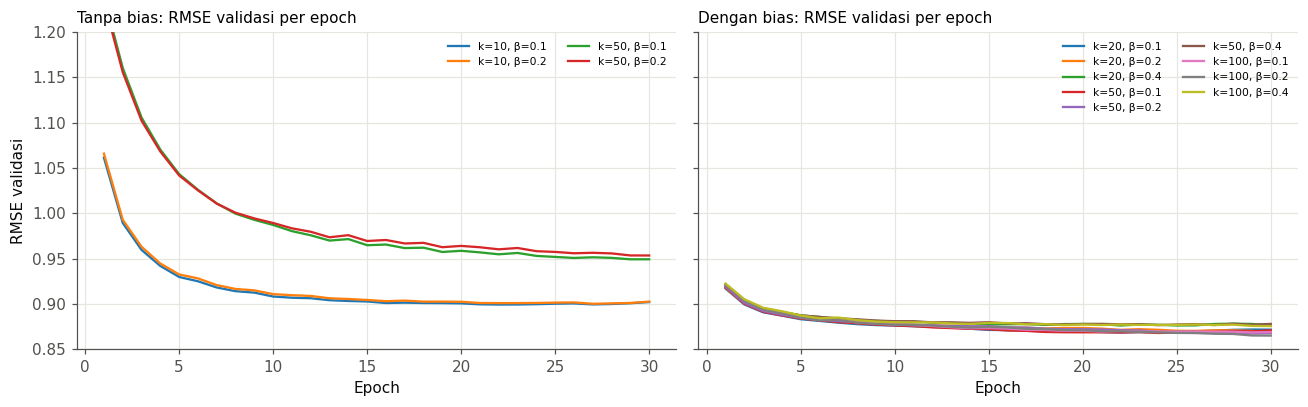

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, curves, title in [(axes[0], curves_nobias, "Tanpa bias"), (axes[1], curves_bias, "Dengan bias")]:
    for (k, beta), h in curves.items():
        ax.plot(h.epoch, h.eval_rmse, lw=1.5, label=f"k={k}, β={beta}")
    ax.set_title(f"{title}: RMSE validasi per epoch", loc="left", fontsize=10)
    ax.set_xlabel("Epoch")
    ax.legend(frameon=False, fontsize=7, ncol=2)
axes[0].set_ylabel("RMSE validasi")
axes[0].set_ylim(0.85, 1.2)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "tuning_sgd.png"), bbox_inches="tight")
plt.show()

### Pengaruh learning rate α
Pada SGD, nilai learning rate α perlu dipilih dengan hati-hati. Kalau terlalu kecil, model lambat belajar. Kalau terlalu besar, error bisa naik turun atau bahkan meledak. Karena itu model dengan bias (k dan β terbaik) kami latih ulang dengan beberapa nilai α. Kalau RMSE meledak, pelatihan dihentikan dan ditandai "divergen".

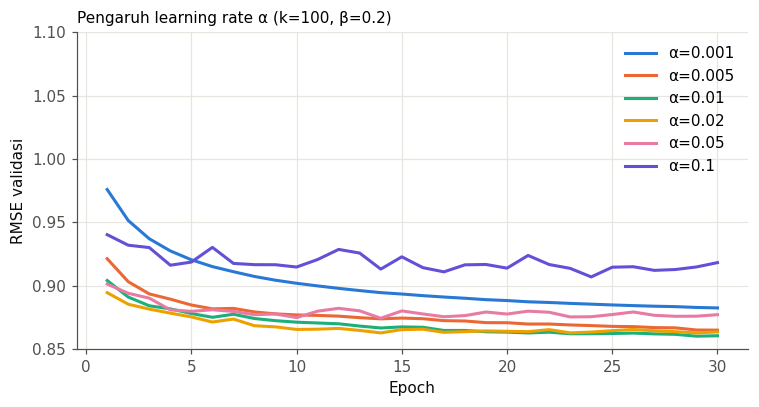

Alpha terbaik: 0.01 (epoch 29), dipakai untuk model akhir


,alpha,val_rmse_terbaik,epoch_terbaik,status
0,0.001,0.882544,30,konvergen
1,0.005,0.865023,30,konvergen
2,0.010,0.860263,29,konvergen
3,0.020,0.862818,29,konvergen
4,0.050,0.874408,14,konvergen
5,0.100,0.907002,24,konvergen


In [8]:
ALPHAS = [0.001, 0.005, 0.01, 0.02, 0.05, 0.1]
alpha_rows, alpha_curves = [], {}
for a in ALPHAS:
    m = SGDMF(n_factors=int(best_b.k), alpha=a, beta=best_b.beta, n_epochs=30, use_bias=True).fit(train, eval_df=val)
    h = pd.DataFrame(m.history)
    alpha_curves[a] = h
    diverged = not np.isfinite(h.train_rmse.iloc[-1]) or h.train_rmse.iloc[-1] > 10
    alpha_rows.append({"alpha": a, "val_rmse_terbaik": np.nan if diverged else h.eval_rmse.min(),
                       "epoch_terbaik": np.nan if diverged else int(h.loc[h.eval_rmse.idxmin(), "epoch"]),
                       "status": "divergen" if diverged else "konvergen"})
alpha_tbl = pd.DataFrame(alpha_rows)
alpha_tbl.to_csv(os.path.join(RESULTS_DIR, "sensitivitas_alpha.csv"), index=False)

fig, ax = plt.subplots(figsize=(7, 3.8))
colors = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, "#6250d6"]
for (a, h), c in zip(alpha_curves.items(), colors):
    ok = np.isfinite(h.eval_rmse) & (h.eval_rmse < 5)
    ax.plot(h.epoch[ok], h.eval_rmse[ok], lw=2, color=c, label=f"α={a}")
ax.set_ylim(0.85, 1.1)
ax.set_xlabel("Epoch"); ax.set_ylabel("RMSE validasi")
ax.set_title(f"Pengaruh learning rate α (k={int(best_b.k)}, β={best_b.beta})", loc="left", fontsize=10)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "sensitivitas_alpha.png"), bbox_inches="tight")
plt.show()

ok_alpha = alpha_tbl.dropna(subset=["val_rmse_terbaik"])
BEST_ALPHA = float(ok_alpha.loc[ok_alpha.val_rmse_terbaik.idxmin(), "alpha"])
BEST_ALPHA_EPOCH = int(ok_alpha.loc[ok_alpha.val_rmse_terbaik.idxmin(), "epoch_terbaik"])
print(f"Alpha terbaik: {BEST_ALPHA} (epoch {BEST_ALPHA_EPOCH}), dipakai untuk model akhir")
alpha_tbl

## 7. Training Model Akhir
Kedua varian dilatih ulang memakai seluruh data train dengan parameter terbaik. Untuk model dengan bias, nilai $k$ dan $\beta$ diambil dari hasil tuning, sedangkan $\alpha$ dan jumlah epoch diambil dari percobaan learning rate. Semua parameter dipilih berdasarkan data validasi. RMSE pada data test di setiap epoch hanya dicatat untuk grafik, tidak dipakai untuk memilih parameter.

SGD-MF tanpa bias : 22 epoch, 30.0 detik
SGD-MF dengan bias: 29 epoch, 48.4 detik


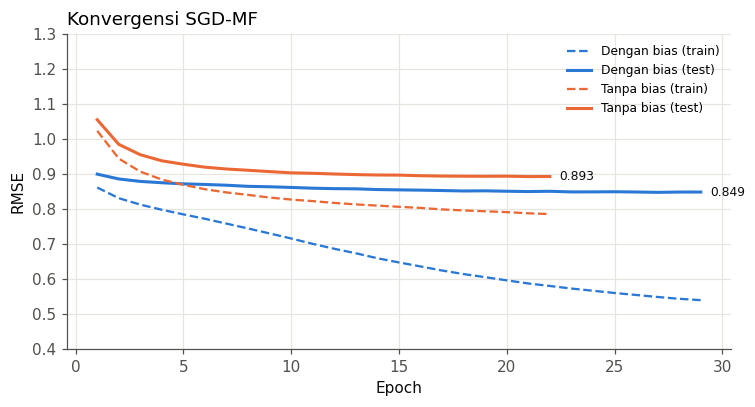

In [9]:
t0 = time.time()
sgd_nobias = SGDMF(n_factors=int(best_nb.k), alpha=0.002, beta=best_nb.beta, n_epochs=int(best_nb.best_epoch),
                   use_bias=False).fit(train_full, eval_df=test)
waktu_nobias = time.time() - t0
t0 = time.time()
sgd_bias = SGDMF(n_factors=int(best_b.k), alpha=BEST_ALPHA, beta=best_b.beta, n_epochs=BEST_ALPHA_EPOCH,
                 use_bias=True).fit(train_full, eval_df=test)
waktu_bias = time.time() - t0
print(f"SGD-MF tanpa bias : {sgd_nobias.n_epochs} epoch, {waktu_nobias:.1f} detik")
print(f"SGD-MF dengan bias: {sgd_bias.n_epochs} epoch, {waktu_bias:.1f} detik")

fig, ax = plt.subplots(figsize=(7, 3.8))
for m, c, name in [(sgd_bias, BLUE, "Dengan bias"), (sgd_nobias, ORANGE, "Tanpa bias")]:
    h = pd.DataFrame(m.history)
    ax.plot(h.epoch, h.train_rmse, color=c, lw=1.5, ls="--", label=f"{name} (train)")
    ax.plot(h.epoch, h.eval_rmse, color=c, lw=2, label=f"{name} (test)")
    ax.annotate(f"{h.eval_rmse.iloc[-1]:.3f}", (h.epoch.iloc[-1], h.eval_rmse.iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=8, color=INK)
ax.set_xlabel("Epoch"); ax.set_ylabel("RMSE")
ax.set_ylim(0.4, 1.3)
ax.set_title("Konvergensi SGD-MF", loc="left")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "konvergensi_sgd.png"), bbox_inches="tight")
plt.show()

## 8. Evaluasi pada Data Test
Sebagai pembanding dipakai dua baseline sederhana:
- Rata-rata global: semua rating diprediksi sama dengan $\mu$.
- Populer: merekomendasikan film yang paling banyak dirating (hanya untuk metrik top-N).

Kalau file `ALS/results/metrics_als.csv` ada, hasil ALS eksplisit (split dan metrik yang sama) juga ikut ditampilkan sebagai pembanding.

In [10]:
res = test.copy()
res["pred_nobias"] = sgd_nobias.predict(res.u.values, res.i.values)
res["pred_bias"] = sgd_bias.predict(res.u.values, res.i.values)
res["pred_mean"] = train_full.rating.mean()
res["score_pop"] = n_rating_item[res.i.values].astype(float)
save_predictions(res, "pred_bias", "sgd_mf")
save_predictions(res, "pred_nobias", "sgd_mf_tanpa_bias")
save_top10(sgd_bias.score_matrix(), "sgd_mf")

NAME_NOBIAS = f"SGD-MF tanpa bias (k={int(best_nb.k)}, α=0.002, β={best_nb.beta:g})"
NAME_BIAS = f"SGD-MF dengan bias (k={int(best_b.k)}, α={BEST_ALPHA:g}, β={best_b.beta:g})"
rows = {}
for name, col, S in [(NAME_NOBIAS, "pred_nobias", sgd_nobias.score_matrix()),
                     (NAME_BIAS, "pred_bias", sgd_bias.score_matrix()),
                     ("Baseline rata-rata global", "pred_mean", None),
                     ("Baseline populer", "score_pop", S_POP)]:
    row = rating_metrics(res, col) if col != "score_pop" else {}
    row.update({"NDCG@5": ndcg_at_k(res, col, 5), "NDCG@10": ndcg_at_k(res, col, 10)})
    if S is not None:
        p, r, f = precision_recall_f1_at_k(top_n_from_scores(S, train_full, 10), test, k=10)
        row.update({"Precision@10": p, "Recall@10": r, "F1@10": f})
    rows[name] = row
metrics = pd.DataFrame.from_dict(rows, orient="index")
metrics.loc[NAME_NOBIAS, "Waktu training (detik)"] = waktu_nobias
metrics.loc[NAME_BIAS, "Waktu training (detik)"] = waktu_bias

als_path = os.path.join("..", "ALS", "results", "metrics_als.csv")
if os.path.exists(als_path):
    als_row = pd.read_csv(als_path, index_col=0).iloc[[0]]          # baris ALS eksplisit
    metrics = pd.concat([als_row, metrics])
metrics.index.name = "Model"
metrics.to_csv(os.path.join(RESULTS_DIR, "metrics_sgd.csv"), float_format="%.4f")
metrics.round(4)

,MAE,MSE,RMSE,NMSE,NDCG@5,NDCG@10,Precision@10,Recall@10,F1@10,Waktu training (detik)
Model,,,,,,,,,,
"ALS eksplisit (k=100, λ=0.1)",0.6502,0.7223,0.8499,0.0357,0.8938,0.9154,0.0033,0.0037,0.0035,NaN
"SGD-MF tanpa bias (k=10, α=0.002, β=0.1)",0.6909,0.7981,0.8934,0.0394,0.8761,0.9006,0.0012,0.0012,0.0012,30.0283
"SGD-MF dengan bias (k=100, α=0.01, β=0.2)",0.6509,0.7208,0.8490,0.0356,0.8940,0.9152,0.0100,0.0112,0.0106,48.4184
Baseline rata-rata global,0.8284,1.0914,1.0447,0.0539,0.8216,0.8555,NaN,NaN,NaN,NaN
Baseline populer,NaN,NaN,NaN,NaN,0.8655,0.8885,0.1194,0.0960,0.1065,NaN


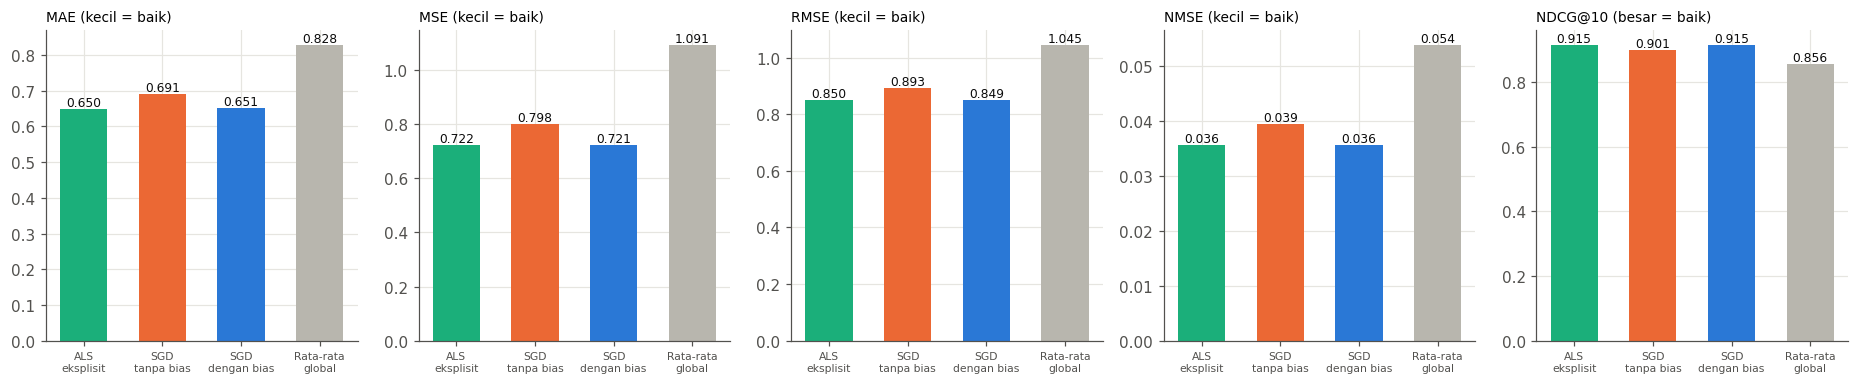

In [11]:
order = [i for i in metrics.index if not np.isnan(metrics.loc[i, "RMSE"])]
short = {i: ("ALS\neksplisit" if i.startswith("ALS") else "SGD\ndengan bias" if "dengan bias" in i
             else "SGD\ntanpa bias" if i.startswith("SGD") else "Rata-rata\nglobal") for i in order}
palette = {i: (AQUA if i.startswith("ALS") else BLUE if "dengan bias" in i
               else ORANGE if i.startswith("SGD") else "#b8b6ae") for i in order}
metrik_plot = ["MAE", "MSE", "RMSE", "NMSE", "NDCG@10"]
fig, axes = plt.subplots(1, len(metrik_plot), figsize=(17, 3.6))
for ax, m in zip(axes, metrik_plot):
    vals = metrics.loc[order, m]
    ax.bar([short[i] for i in order], vals, color=[palette[i] for i in order], width=0.6)
    for x, v in enumerate(vals):
        ax.text(x, v, f"{v:.3f}", ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_title(f"{m} ({'besar' if m.startswith('NDCG') else 'kecil'} = baik)", loc="left", fontsize=9)
    ax.tick_params(axis="x", labelsize=7)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "perbandingan_sgd.png"), bbox_inches="tight")
plt.show()

## 9. Contoh Prediksi Rating dan Rekomendasi untuk User 1
Berikut 10 film yang direkomendasikan model SGD-MF dengan bias untuk user 1. Kolom `rating_asli_di_test` menunjukkan apakah film itu memang ditonton user 1 di data test.

In [12]:
CONTOH_USER = 1

def recommend_for_user(S, user_id, n=10, pred_rating=None):
    u = u_index[user_id]
    row = S[u].astype(float).copy()
    row[n_rating_item == 0] = -np.inf
    row[train_full.loc[train_full.u == u, "i"].values] = -np.inf
    top = np.argsort(-row, kind="stable")[:n]
    actual = dict(zip(test.loc[test.u == u, "i"], test.loc[test.u == u, "rating"]))
    rec = pd.DataFrame({"movieId": item_ids[top], "title": [title_of[item_ids[i]] for i in top]},
                       index=pd.RangeIndex(1, n + 1, name="rank"))
    if pred_rating is not None:
        rec["prediksi_rating"] = np.round(pred_rating(u, top), 2)
    rec["jumlah_rating_film"] = n_rating_item[top]
    rec["rating_asli_di_test"] = [actual.get(i, "-") for i in top]
    return rec

In [13]:
rec = recommend_for_user(sgd_bias.score_matrix(), CONTOH_USER,
                         pred_rating=lambda u, items: sgd_bias.predict(np.full(len(items), u), items))
print(f"Top-10 untuk user {CONTOH_USER} ({(rec.rating_asli_di_test != '-').sum()} dari 10 ada di data test):")
rec

Top-10 untuk user 1 (0 dari 10 ada di data test):


,movieId,title,prediksi_rating,jumlah_rating_film,rating_asli_di_test
rank,,,,,
1,26810,Bad Boy Bubby (1993),5.0,3,-
2,6442,Belle époque (1992),5.0,2,-
3,8477,"Jetée, La (1962)",5.0,2,-
4,43376,Sophie Scholl: The Final Days (Sophie Scholl -...,5.0,4,-
5,27156,Neon Genesis Evangelion: The End of Evangelion...,5.0,5,-
6,89904,The Artist (2011),5.0,9,-
7,187,Party Girl (1995),5.0,3,-
8,318,"Shawshank Redemption, The (1994)",5.0,248,-
9,132333,Seve (2014),5.0,1,-


In [14]:
cek = res[res.userId == CONTOH_USER].assign(title=lambda d: d.movieId.map(title_of)).sort_values("pred_bias", ascending=False)
cek[["title", "rating", "pred_bias", "pred_nobias"]].rename(
    columns={"rating": "rating_asli", "pred_bias": "dengan bias", "pred_nobias": "tanpa bias"}).round(2).head(10)

,title,rating_asli,dengan bias,tanpa bias
1,Star Wars: Episode IV - A New Hope (1977),5.0,4.99,5.00
38,Fight Club (1999),5.0,4.94,5.00
2,Pulp Fiction (1994),3.0,4.92,5.00
14,"Shining, The (1980)",3.0,4.88,5.00
4,Forrest Gump (1994),4.0,4.87,4.96
19,L.A. Confidential (1997),5.0,4.77,4.90
10,Reservoir Dogs (1992),5.0,4.77,5.00
15,Back to the Future (1985),5.0,4.74,4.73
13,Duck Soup (1933),5.0,4.64,4.52
33,Planet of the Apes (1968),5.0,4.61,4.78


## 10. Analisis dan Kesimpulan

### Analisis

**1. Uji coba pada matriks kecil**
Pada matriks 5×4, setelah 5000 step rating yang sudah ada bisa didekati dengan baik (5 menjadi 5,07, 1 menjadi 1,01, 4 menjadi 3,97), dan sel kosong ikut terisi prediksi. Ini menunjukkan aturan update SGD yang kami pakai sudah benar. Versi untuk dataset asli (`class SGDMF`) memakai aturan update yang sama, hanya ditulis dengan operasi vektor supaya bisa jalan pada 80 ribu rating.

**2. Pengaruh bias**
Model tanpa bias hanya mencapai RMSE test 0,893, dan hasil terbaiknya didapat dengan k kecil (k=10). Waktu k dinaikkan ke 50, RMSE validasinya malah naik ke 0,949. Menurut kami ini karena tanpa bias, faktor laten harus menanggung semuanya sekaligus: rata-rata rating, user yang memang suka memberi nilai tinggi atau rendah, dan film yang memang bagus atau jelek.

Setelah ditambah $\mu + b_u + b_i$, RMSE test turun menjadi 0,849. Model juga bisa memakai k yang lebih besar (k=100) tanpa overfitting, asalkan regularisasinya cukup. β=0,2 memberi hasil terbaik, sedangkan β=0,4 terlalu kuat sehingga model underfit.

**3. Pengaruh learning rate α**
Dari percobaan dengan k=100, β=0,2, dan 30 epoch:
- α=0,001 terlalu lambat. Sampai epoch 30 RMSE validasi masih 0,883 dan masih terus turun.
- α=0,01 memberi hasil terbaik, yaitu 0,860 di epoch 29. Ini sedikit lebih baik dari α=0,005 yang kami pakai saat tuning (0,865).
- α=0,05 lebih cepat mencapai titik terbaiknya (epoch 14), tetapi setelah itu grafiknya naik turun dan hasilnya memburuk. Dengan α=0,1 grafiknya sudah naik turun dari awal, dan RMSE terbaiknya hanya 0,907.

Jadi untuk model akhir kami memakai α=0,01. Dari percobaan ini terlihat bahwa α adalah parameter yang paling sensitif pada SGD. Kalau langkahnya terlalu besar, update parameter melewati titik minimum dan error-nya tidak stabil.

**4. Konvergensi dan overfitting**
Pada grafik konvergensi, RMSE train model dengan bias terus turun sampai sekitar 0,54, sedangkan RMSE test berhenti turun di sekitar 0,85. Selisih ini menunjukkan model tetap sedikit overfitting. Overfitting tersebut dibatasi oleh regularisasi β dan oleh jumlah epoch yang dipilih dari data validasi (early stopping).

**5. Perbandingan dengan baseline dan ALS**
Model dengan bias jauh lebih baik dari baseline rata-rata global di semua metrik: MAE 0,651 vs 0,828, RMSE 0,849 vs 1,045, NDCG@10 0,915 vs 0,856.

Kami juga membandingkannya dengan ALS eksplisit yang memakai data dan metrik yang sama. Hasilnya hampir sama: RMSE 0,849 (SGD) vs 0,850 (ALS), MAE 0,651 vs 0,650, NDCG@10 0,915 vs 0,915. Hal ini masuk akal karena keduanya meminimalkan fungsi error yang sama (squared error ditambah regularisasi), hanya cara optimasinya yang berbeda. ALS tidak membutuhkan learning rate dan cukup sekitar 15 iterasi. SGD perlu α yang dipilih dengan tepat dan sekitar 30 epoch, tetapi lebih mudah dikembangkan, misalnya untuk menambah komponen baru ke model atau memperbarui model saat ada rating baru.

**6. Kelemahan untuk rekomendasi top-N**
Walaupun prediksi ratingnya bagus, rekomendasi top-10 dari model ini kurang tepat: F1@10 hanya 0,011, jauh di bawah baseline populer (0,107). Contohnya pada user 1, hampir semua film yang direkomendasikan adalah film yang hanya punya 1 sampai 9 rating (misalnya *Bad Boy Bubby* dan *Belle époque*). Satu-satunya film populer adalah *Shawshank Redemption*. Semuanya diprediksi bernilai 5,0, tetapi tidak satu pun ada di data test user 1.

Penyebabnya, model hanya belajar dari rating yang ada. Film yang ratingnya sedikit tetapi tinggi semua akan mendapat bias item yang besar, sehingga skornya naik ke atas. Model tidak tahu bahwa film tersebut jarang ditonton orang. Jadi model ini cocok untuk menebak berapa rating yang akan diberikan user pada sebuah film, tetapi kurang cocok untuk memilih film mana yang kemungkinan akan ditonton.

### Kesimpulan
1. Model SGD-MF terbaik adalah varian dengan bias (k=100, α=0,01, β=0,2, 29 epoch). Hasilnya pada data test: MAE 0,651, MSE 0,721, RMSE 0,849, NMSE 0,036, dan NDCG@10 0,915.
2. Penambahan bias global, bias user, dan bias item menurunkan RMSE dari 0,893 menjadi 0,849.
3. Learning rate sangat menentukan hasil SGD. Nilai yang terlalu kecil membuat model lambat belajar, sedangkan nilai yang terlalu besar membuat error tidak stabil.
4. Hasil SGD-MF setara dengan ALS eksplisit (RMSE 0,849 vs 0,850).
5. Untuk rekomendasi top-N, model ini masih lemah (F1@10 0,011) karena cenderung merekomendasikan film yang jarang ditonton.